# Ion inertial length in Jupiyer's magnetosphere

In [1]:
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt

from matplotlib.ticker import AutoMinorLocator

from JunoPy.spice import InitSpiceKernels, get_juno_position

## 1. Calculate the variation of density with radial distance. 

In [2]:
r = np.linspace(6, 100, 100)

# Bagenal and Delamere (2011) model
a1 = 1987
a2 = 14
a3 = 0.05
b1 = -8.2
b2 = -3.2
b3 = -0.65

n = a1 * (r / 6)**(b1) + a2 * (r / 6)**(b2) + a3 * (r / 6)**(b3) 


mi = 16.6 * 1.67e-27
qi = 1.6e-19
rhoi = mi * n * 1e6
mu0 = 1.25e-6
di = mi / qi * np.sqrt(1 / rhoi / mu0) / 71492e3

## 2. Read the csv file and estimate spacecraft velocity

In [3]:
def read_csv_file():
    start_times = []
    end_times = []
    durations = []
    with open('mva_epochs.csv', 'r') as f:
        f.readline()
        for line in f:
            start_times.append(dt.datetime.strptime(line.split(',')[0], '%Y-%jT%H:%M:%S'))
            end_times.append(dt.datetime.strptime(line.split(',')[1], '%Y-%jT%H:%M:%S'))
            durations.append(float(line.split(',')[-1]))
    return start_times, end_times, durations
            
start_times, end_times, durations = read_csv_file()
start_positions, _ = get_juno_position(start_times)
end_positions, _ = get_juno_position(end_times)

In [4]:
N = len(start_times)
dt = [(start_times[i] - end_times[i]).seconds for i in range(N)]
dx = np.sqrt(np.sum(start_positions**2, axis=1) - np.sum(end_positions**2, axis=1))
v = dx / dt * 71492e3
r_sc = np.sqrt(np.sum(start_positions**2, axis=1))

## Plot the data.

/Users/sarkango/Envs/JunoPy/lib/python3.7/site-packages/IPython/core/pylabtools.py:128: UserWarning: AutoMinorLocator does not work with logarithmic scale
  fig.canvas.print_figure(bytes_io, **kw)


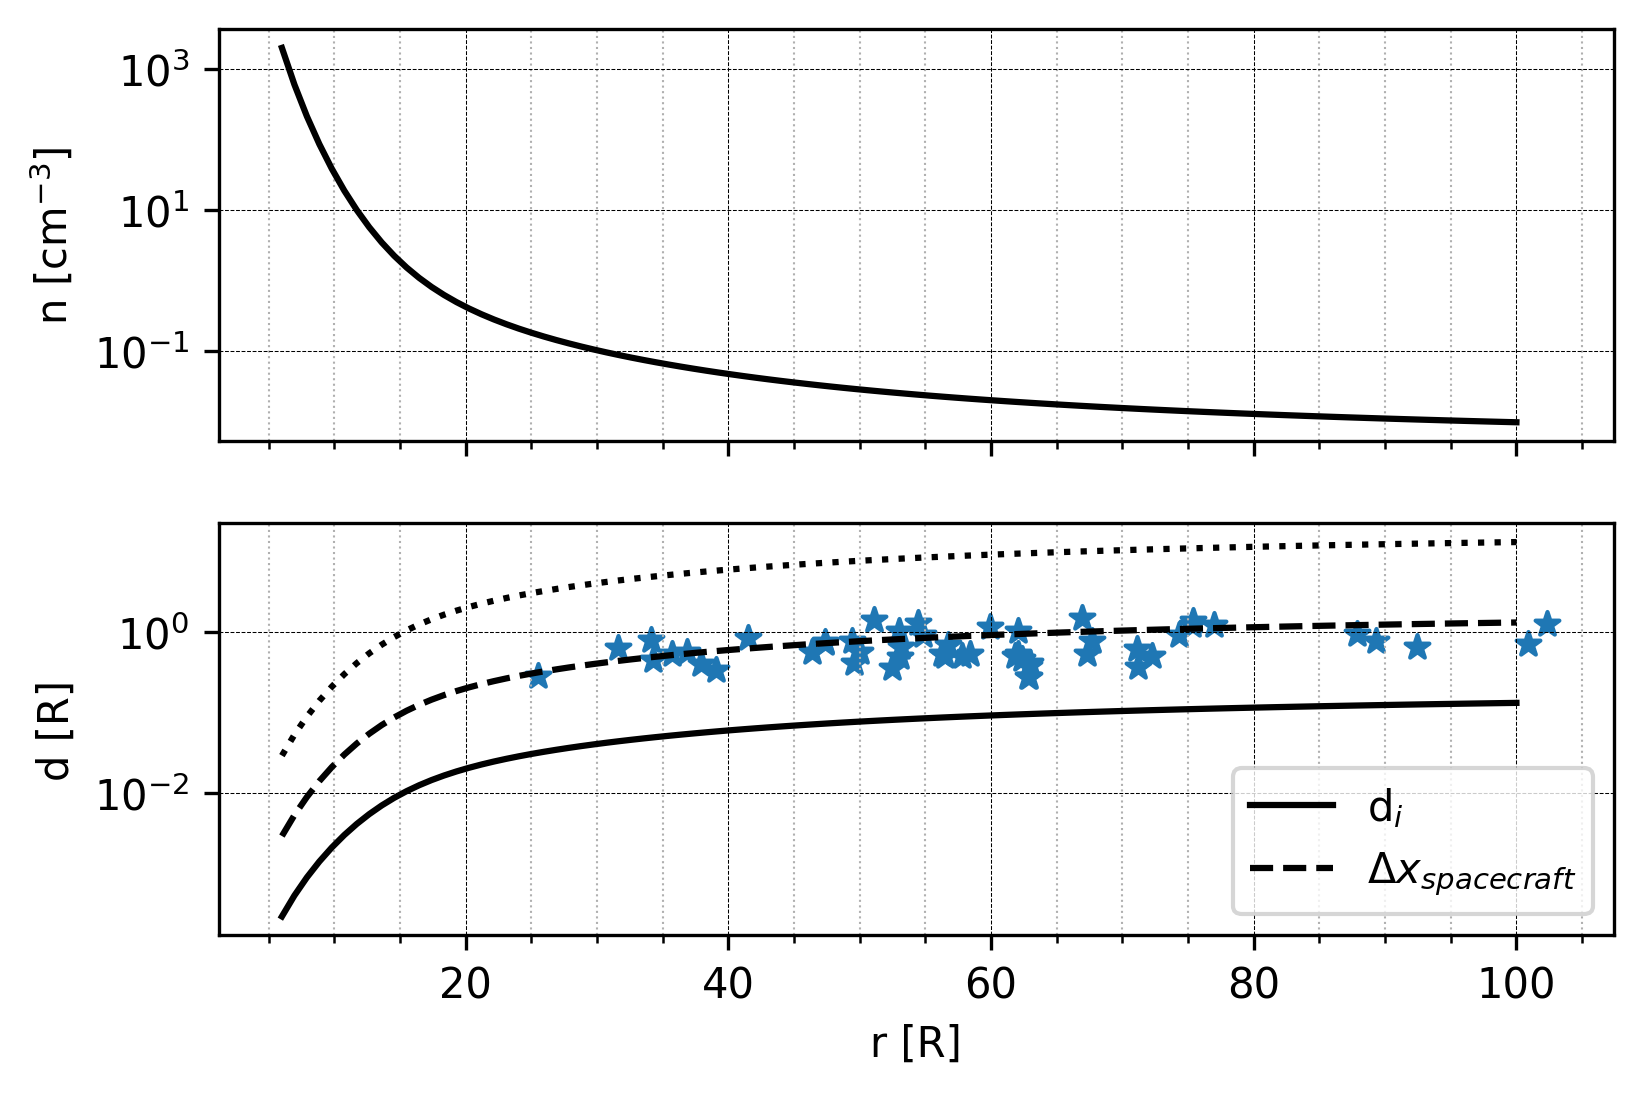

In [5]:
fig, ax = plt.subplots(2, 1, sharex=True, dpi=300)

ax[0].semilogy(r, n, color='k')
ax[0].set_ylabel('n [cm$^{-3}$]')
ax[0].grid()

ax[1].semilogy(r, di, color='k')
ax[1].semilogy(r, di * 10, color='k', ls='dashed')
ax[1].semilogy(r, di * 100, color='k', ls='dotted')
ax[1].scatter(r_sc, dx, marker='*')
ax[1].set_ylabel('d [R]')
ax[1].grid()

ax[1].set_xlabel('r [R]')

for a in ax:
    a.xaxis.set_minor_locator(AutoMinorLocator())
    a.yaxis.set_minor_locator(AutoMinorLocator())
    a.grid('on', which='minor', lw=0.5, ls='dotted')
    a.grid(color='k', ls='dashed', lw=0.25)

ax[1].legend(['d$_i$', '$\Delta x$$_{spacecraft}$'])